# Bounded MOIA and FlipFlop Spatial Comparison

This notebook compares the MOIA trip points with the FlipFlop Neubau sample inside one explicitly defined geographic box.

**Important:** FlipFlop trips outside the box are excluded from the visualizations below. The notebook reports that cutoff so this bounded view is not mistaken for the full FlipFlop population or the full hypothesis analysis.

## Why A Bounded View?

The available FleetPy street geometry covers the central Klagenfurt operating area. The FlipFlop Neubau sample extends beyond that area. Plotting every point against the local street geometry leaves large blank regions and makes the comparison difficult to interpret.

This notebook therefore uses the MOIA dataset's coordinate bounding box as a transparent comparison box. A FlipFlop trip is retained only when both its origin and destination are inside that box. This is appropriate for a spatial comparison with MOIA, but it changes the population and must not replace the full FlipFlop mode-choice analysis.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

MOIA_FILE = ROOT_DIR / 'data' / 'demand' / 'trips_klagenfurt.csv'
FLIPFLOP_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'neubau' / 'draws_Baseline.csv'
NETWORK_FILE = ROOT_DIR / 'klagenfurt_network_extended.gpkg'
NETWORK_NODES_FILE = ROOT_DIR / 'data' / 'networks' / 'klagenfurt_h1_spitzenzeiten' / 'base' / 'nodes.csv'
OUTPUT_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'

moia = pd.read_csv(MOIA_FILE)
flipflop_all = pd.read_csv(FLIPFLOP_FILE, usecols=['draw', 'trip_id', 'drawn_mode', 'lat_start', 'lon_start', 'lat_end', 'lon_end'])
flipflop_all = flipflop_all[flipflop_all['draw'] == 1].copy()
network = gpd.read_file(NETWORK_FILE).to_crs(epsg=3857)
nodes = pd.read_csv(NETWORK_NODES_FILE)
print(f'MOIA trips: {len(moia):,}')
print(f'FlipFlop Draw 1 trips before cutoff: {len(flipflop_all):,}')
print(f'Network street segments: {len(network):,}')

MOIA trips: 1,067
FlipFlop Draw 1 trips before cutoff: 5,173
Network street segments: 8,277


## Define The Study Box

The box is derived from the observed MOIA coordinates rather than chosen visually. It contains all MOIA origins and destinations, and it provides the common spatial frame for both datasets.

In [2]:
all_moia_x = pd.concat([moia['origin_x'], moia['destination_x']])
all_moia_y = pd.concat([moia['origin_y'], moia['destination_y']])
box = {
    'min_lon': all_moia_x.min(),
    'max_lon': all_moia_x.max(),
    'min_lat': all_moia_y.min(),
    'max_lat': all_moia_y.max(),
}
print('MOIA comparison box:')
for key, value in box.items():
    print(f'  {key}: {value:.6f}')

MOIA comparison box:
  min_lon: 14.218684
  max_lon: 14.413207
  min_lat: 46.579880
  max_lat: 46.700038


In [3]:
flipflop_in_box = flipflop_all[
    flipflop_all['lon_start'].between(box['min_lon'], box['max_lon'])
    & flipflop_all['lat_start'].between(box['min_lat'], box['max_lat'])
    & flipflop_all['lon_end'].between(box['min_lon'], box['max_lon'])
    & flipflop_all['lat_end'].between(box['min_lat'], box['max_lat'])
].copy()
cutoff_count = len(flipflop_all) - len(flipflop_in_box)
retained_share = len(flipflop_in_box) / len(flipflop_all)
print(f'FlipFlop trips retained inside box: {len(flipflop_in_box):,} ({retained_share:.1%})')
print(f'FlipFlop trips cut off outside box: {cutoff_count:,} ({1 - retained_share:.1%})')
print('The cutoff is applied to complete trips: both endpoints must be inside the box.')
print('Retained FlipFlop modes:')
print(flipflop_in_box['drawn_mode'].value_counts().to_string())

FlipFlop trips retained inside box: 4,665 (90.2%)
FlipFlop trips cut off outside box: 508 (9.8%)
The cutoff is applied to complete trips: both endpoints must be inside the box.
Retained FlipFlop modes:
drawn_mode
Car     3719
Foot     445
Bike     267
PT       234


## Visualization 1: One Combined Map

This is the main comparison figure. Color identifies the dataset and marker shape identifies the endpoint type: circles are origins and X markers are destinations. Only points inside the MOIA box are shown. The local GeoPackage street layer is included for geographic context.

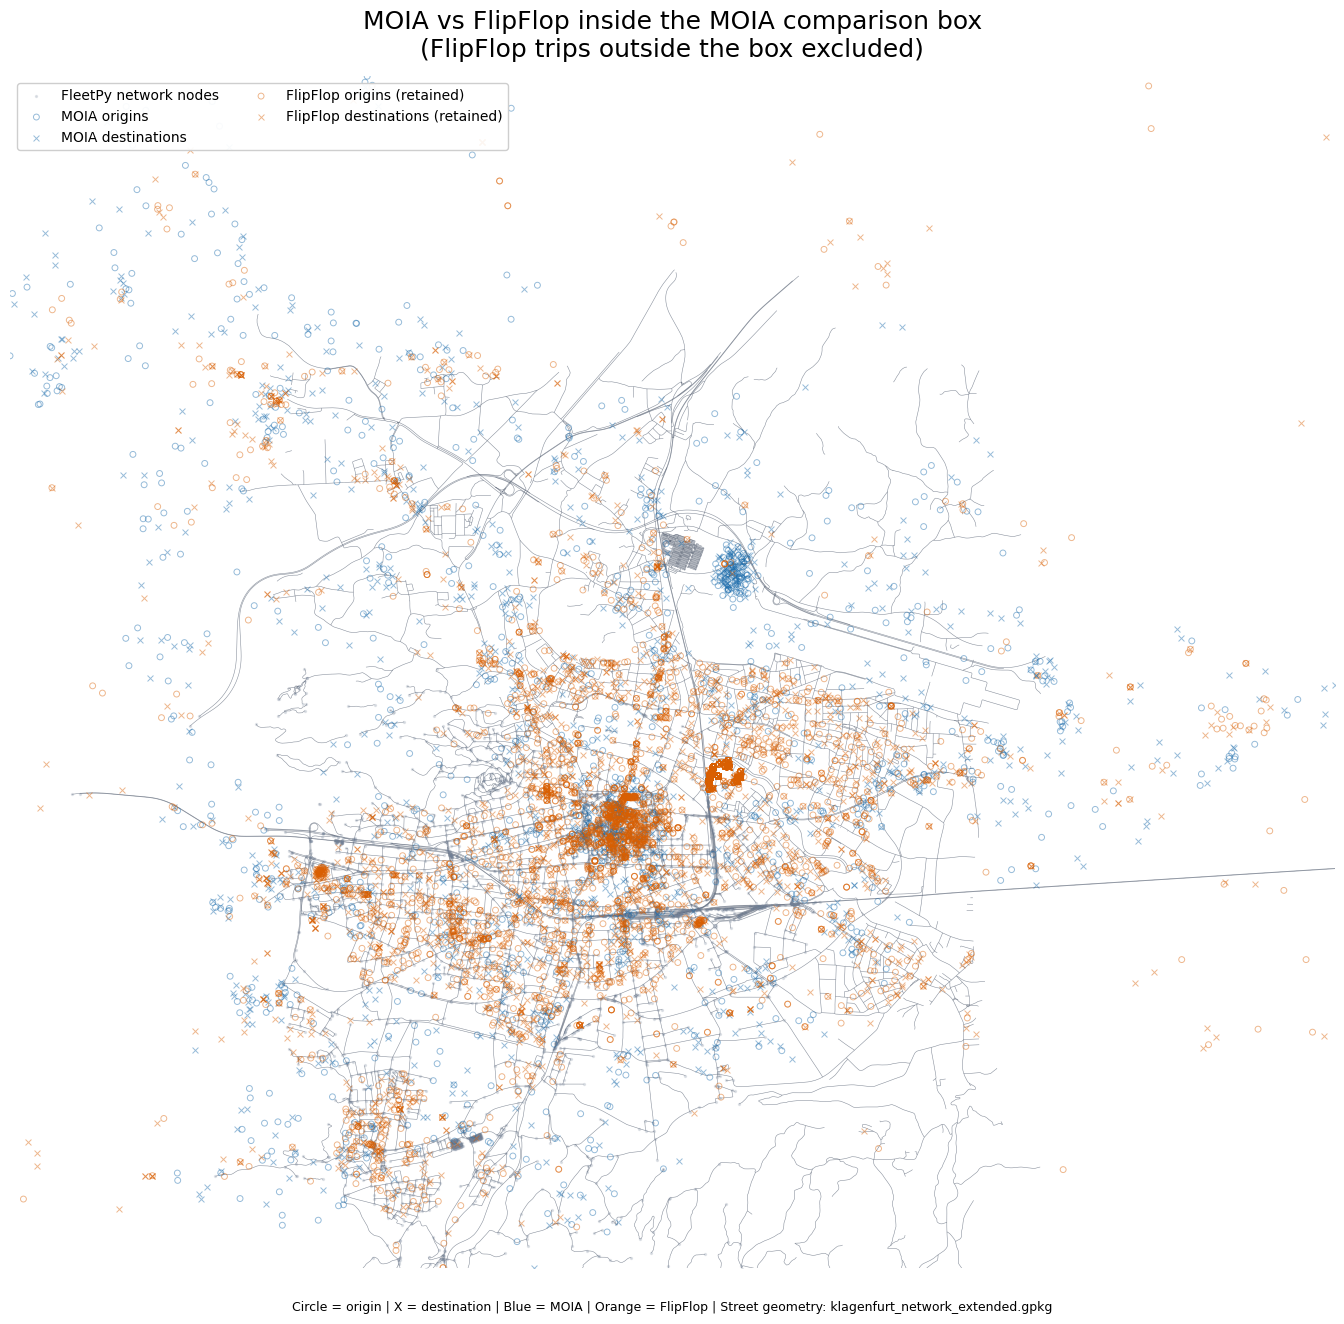

/Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/flipflop_drt_integration_pilot/results/flipflop_vs_moia_bounded_combined_map.png


In [4]:
def web_points(x, y):
    return gpd.GeoSeries(gpd.points_from_xy(x, y), crs='EPSG:4326').to_crs(epsg=3857)

moia_origins = web_points(moia['origin_x'], moia['origin_y'])
moia_destinations = web_points(moia['destination_x'], moia['destination_y'])
flipflop_origins = web_points(flipflop_in_box['lon_start'], flipflop_in_box['lat_start'])
flipflop_destinations = web_points(flipflop_in_box['lon_end'], flipflop_in_box['lat_end'])
network_nodes = web_points(nodes['pos_x'], nodes['pos_y'])

fig, ax = plt.subplots(figsize=(18, 14))
network.plot(ax=ax, linewidth=0.4, color='#4a5568', alpha=0.65, zorder=1)
ax.scatter(network_nodes.x, network_nodes.y, s=2, color='#718096', alpha=0.18, label='FleetPy network nodes', zorder=2)
ax.scatter(moia_origins.x, moia_origins.y, s=18, marker='o', facecolors='none', edgecolors='#1769aa', linewidths=0.7, alpha=0.45, label='MOIA origins', zorder=3)
ax.scatter(moia_destinations.x, moia_destinations.y, s=18, marker='x', color='#1769aa', linewidths=0.7, alpha=0.45, label='MOIA destinations', zorder=3)
ax.scatter(flipflop_origins.x, flipflop_origins.y, s=18, marker='o', facecolors='none', edgecolors='#d95f02', linewidths=0.7, alpha=0.45, label='FlipFlop origins (retained)', zorder=4)
ax.scatter(flipflop_destinations.x, flipflop_destinations.y, s=18, marker='x', color='#d95f02', linewidths=0.7, alpha=0.45, label='FlipFlop destinations (retained)', zorder=4)
ax.set_xlim(*web_points(pd.Series([box['min_lon'], box['max_lon']]), pd.Series([box['min_lat'], box['max_lat']])).total_bounds[[0, 2]])
ax.set_ylim(*web_points(pd.Series([box['min_lon'], box['max_lon']]), pd.Series([box['min_lat'], box['max_lat']])).total_bounds[[1, 3]])
ax.set_title('MOIA vs FlipFlop inside the MOIA comparison box\n(FlipFlop trips outside the box excluded)', fontsize=18, pad=14)
ax.legend(loc='upper left', framealpha=0.95, ncol=2, fontsize=10)
ax.set_axis_off()
fig.text(0.5, 0.02, 'Circle = origin | X = destination | Blue = MOIA | Orange = FlipFlop | Street geometry: klagenfurt_network_extended.gpkg', ha='center', fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
combined_output = OUTPUT_DIR / 'flipflop_vs_moia_bounded_combined_map.png'
fig.savefig(combined_output, dpi=180, bbox_inches='tight')
plt.show()
print(combined_output)

## Interpretation And Limits

- The figures answer a spatial-comparison question inside the MOIA box.
- They do not describe the full geographic distribution of FlipFlop Neubau trips.
- They do not replace the full FlipFlop mode-choice hypothesis test.
- The cutoff is necessary to make the MOIA comparison and local street context readable.
- For FleetPy operations, an additional routability filter is still required because a point can be inside the box but belong to a disconnected part of the street graph.
- Any operational result should report both the retained request count and the excluded-trip count.